Training Yolov8 model on Custom Dataset

In [ ]:
import torch
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))


GPU Available: True
GPU Name: Tesla T4


In [ ]:
!nvidia-smi

Tue May 26 07:15:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#### Training Configuration and overview

In [ ]:
path_to_classes_txt='/content/drive/MyDrive/Vehicle_Data/DataSet/classes.txt'
path_to_data_yaml='/content/drive/MyDrive/Vehicle_Data/DataSet/data.yaml'

print('Files Contains:\n')
!cat /content/drive/MyDrive/Vehicle_Data/DataSet/data.yaml

Files Contains:

# paths of folders 
path: /content/drive/MyDrive/Vehicle_Data # root folder path
train: DataSet/train/images # train folder path
val: DataSet/val/images # val folder path

# Number of Classes
nc: 3

# Classes
names:
  0: bicycle
  1: car
  2: bike

#### Install Requirements

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 32.7 MB/s eta 0:00:00


#### Deleting old cache files

In [ ]:
!rm -f /content/drive/MyDrive/Vehicle_Data/DataSet/train/images.cache
!rm -f /content/drive/MyDrive/Vehicle_Data/DataSet/val/images.cache
!rm -f /content/drive/MyDrive/Vehicle_Data/DataSet/train/labels.cache
!rm -f /content/drive/MyDrive/Vehicle_Data/DataSet/val/labels.cache

Deleing previous weight

In [ ]:
# Also delete the failed run's weights
!rm -rf /content/runs/

#### Run Training

In [ ]:
!yolo detect train data=/content/drive/MyDrive/Vehicle_Data/DataSet/data.yaml model=yolov8m.pt epochs=100 imgsz=640 patience=0 project=/content/drive/MyDrive/Vehicle_Data/runs

Ultralytics 8.4.54 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Vehicle_Data/DataSet/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overl

#### Listing all the obtained stuffs after training

In [ ]:
!ls /content/drive/MyDrive/Vehicle_Data/runs/train

args.yaml			 results.csv	      val_batch0_labels.jpg
BoxF1_curve.png			 results.png	      val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg     val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg     val_batch1_pred.jpg
BoxR_curve.png			 train_batch2.jpg     val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch4950.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch4951.jpg  weights
labels.jpg			 train_batch4952.jpg


#### Now we display some results we obtained

In [ ]:
!pip install Ipython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 71.3 MB/s eta 0:00:00


In [ ]:
from IPython.display import Image, display

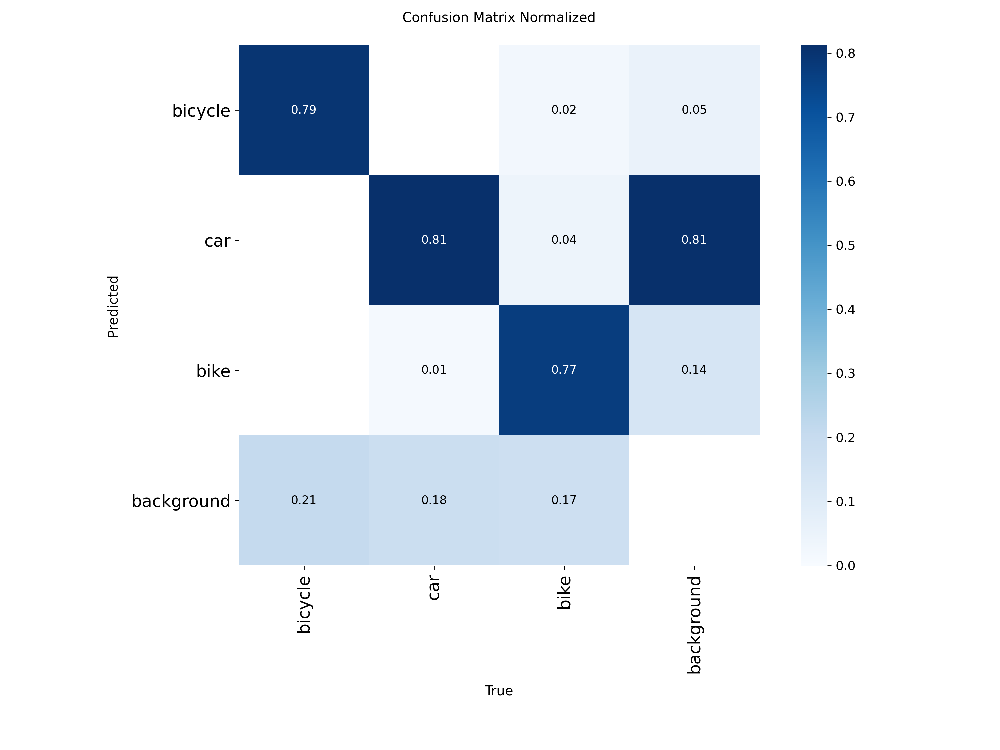

In [ ]:
Image(filename='/content/drive/MyDrive/Vehicle_Data/runs/train/confusion_matrix_normalized.png', width=600)

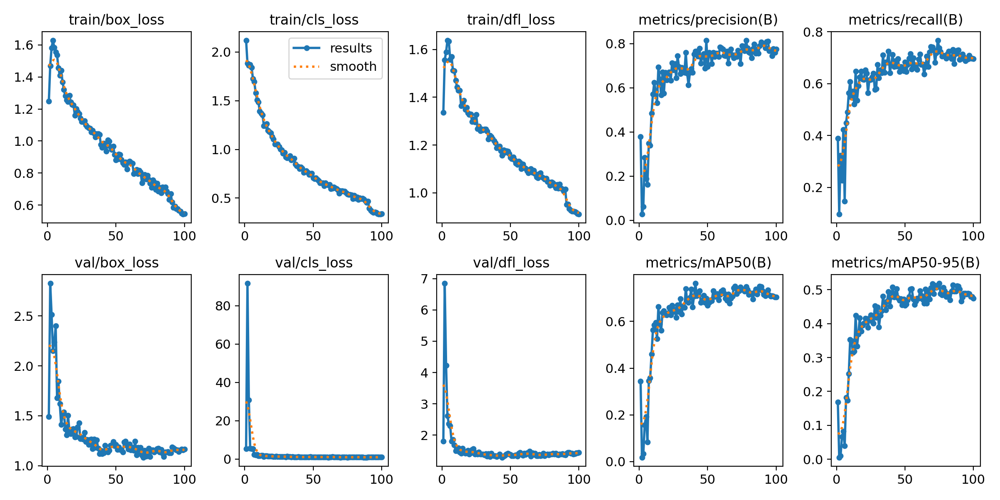

In [ ]:
Image(filename='/content/drive/MyDrive/Vehicle_Data/runs/train/results.png',width=700)

### Save Model to Drive

In [ ]:
# Auto-backup weights to Drive after training completes
import shutil, os

src = "/content/drive/MyDrive/Vehicle_Data/runs/train/weights/"
dst = "/content/drive/MyDrive/Vehicle_Data/runs/trained_model/weights/"

os.makedirs(dst, exist_ok=True)
shutil.copy(src + "best.pt",  dst + "best.pt")
shutil.copy(src + "last.pt",  dst + "last.pt")
print("✅ Weights backed up to Google Drive!")

✅ Weights backed up to Google Drive!


### Testing Model
 *Inferencing on validation set. And then displaying first 10 images.*

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 21.6 MB/s eta 0:00:00


In [ ]:
!yolo detect predict model=/content/drive/MyDrive/Vehicle_Data/runs/train/weights/best.pt source=/content/drive/MyDrive/Vehicle_Data/DataSet/val/images save=True

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.54 🚀 Python-3.12.13 torch-2.10.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 93 layers, 25,841,497 parameters, 0 gradients, 78.7 GFLOPs

image 1/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_274.jpeg: 448x640 1 bicycle, 1615.3ms
image 2/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_275.jpeg: 448x640 1 bicycle, 933.9ms
image 3/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_276.jpeg: 640x448 2 bicycles, 965.5ms
image 4/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_277.jpeg: 448x640 1 bicycle, 964.4ms
image 5/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_27

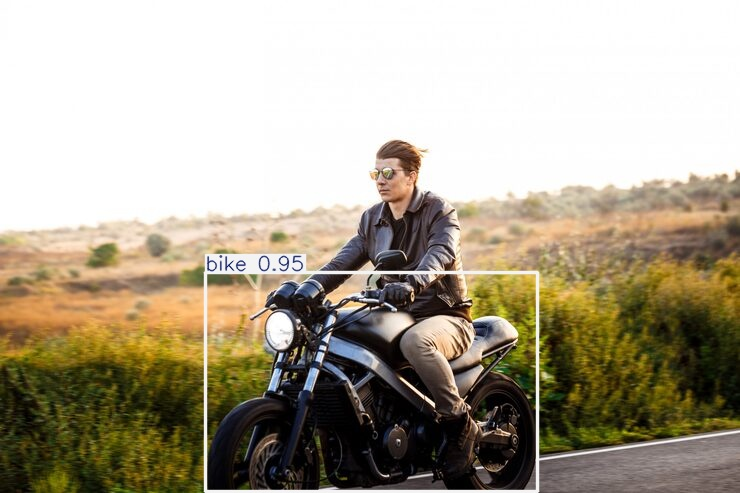

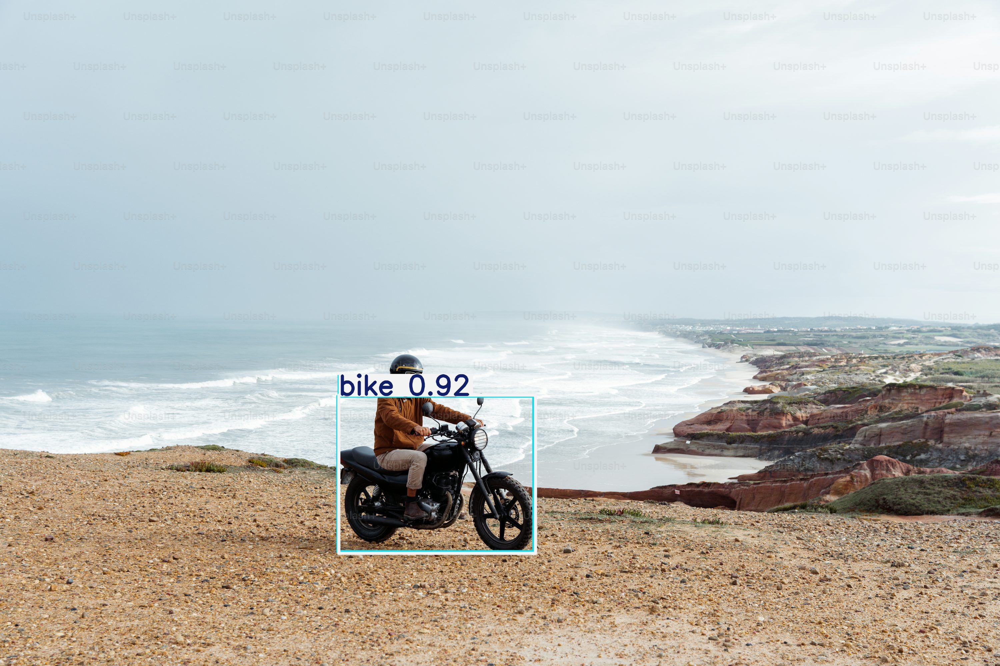

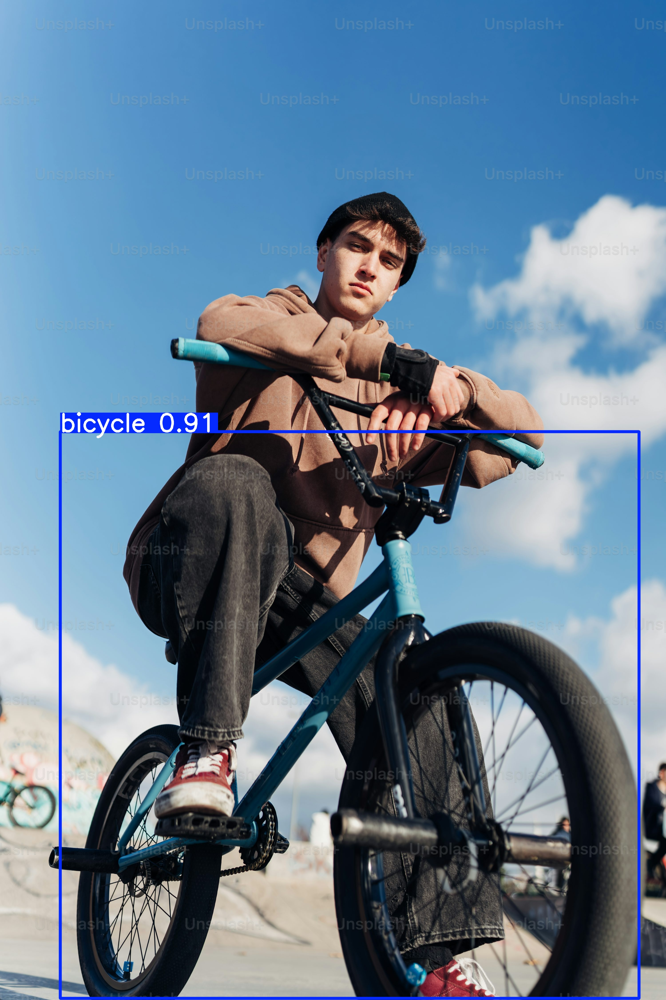

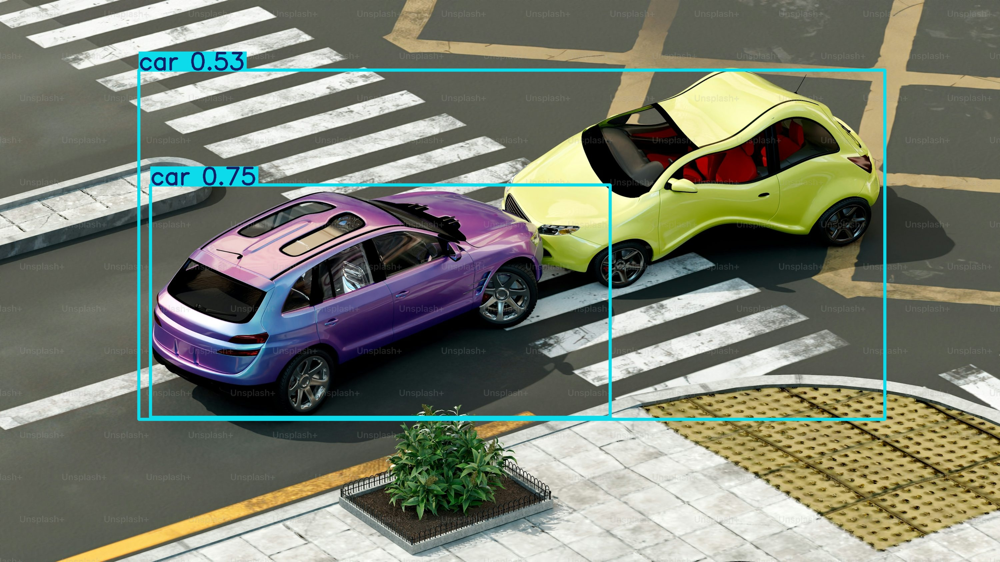

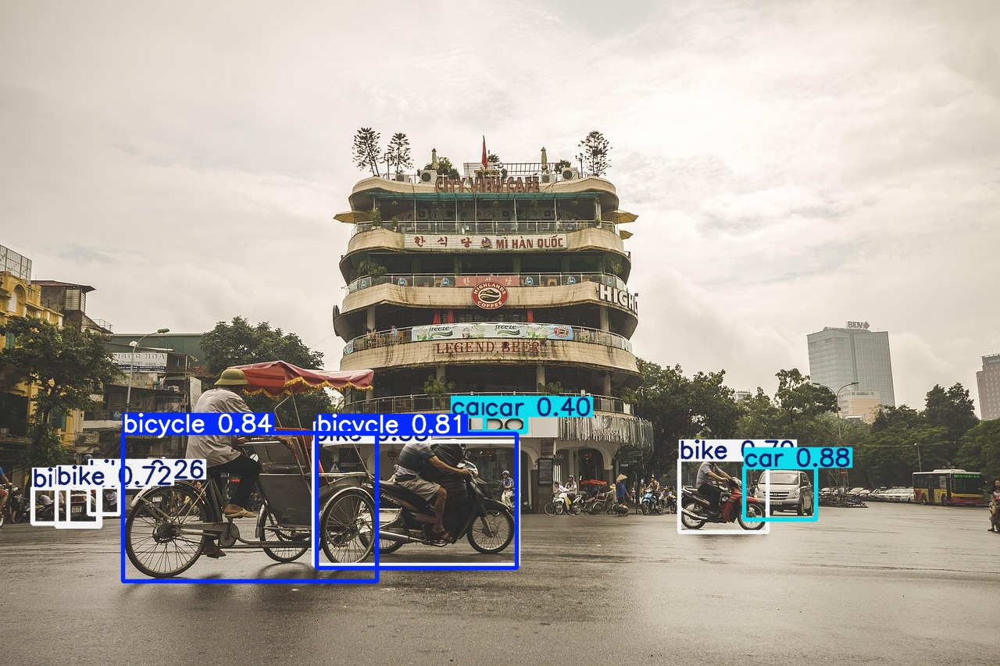

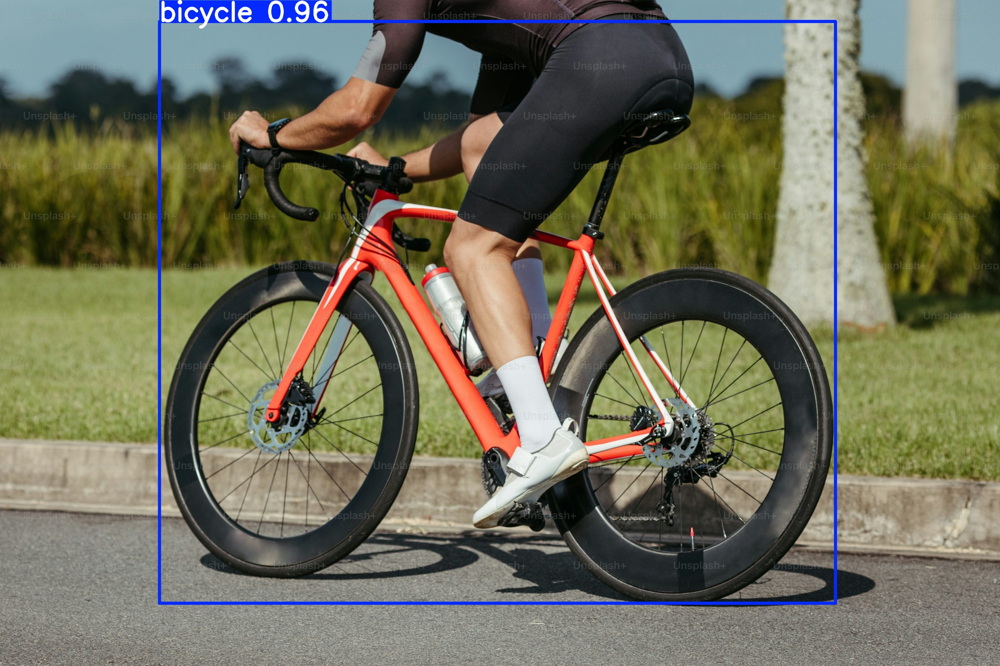

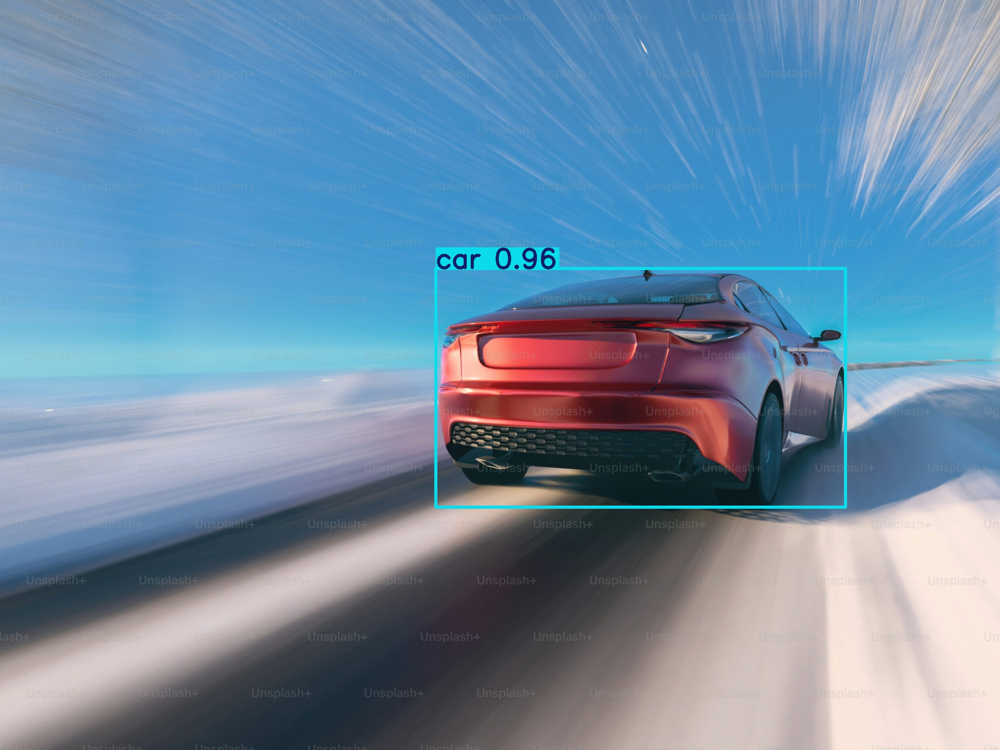

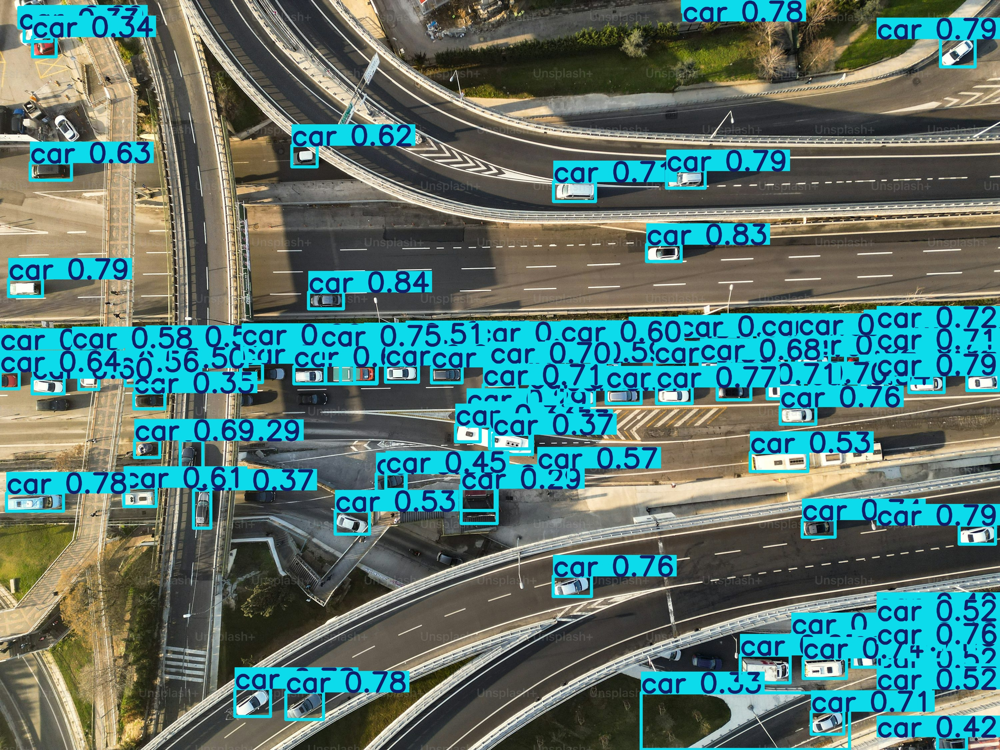

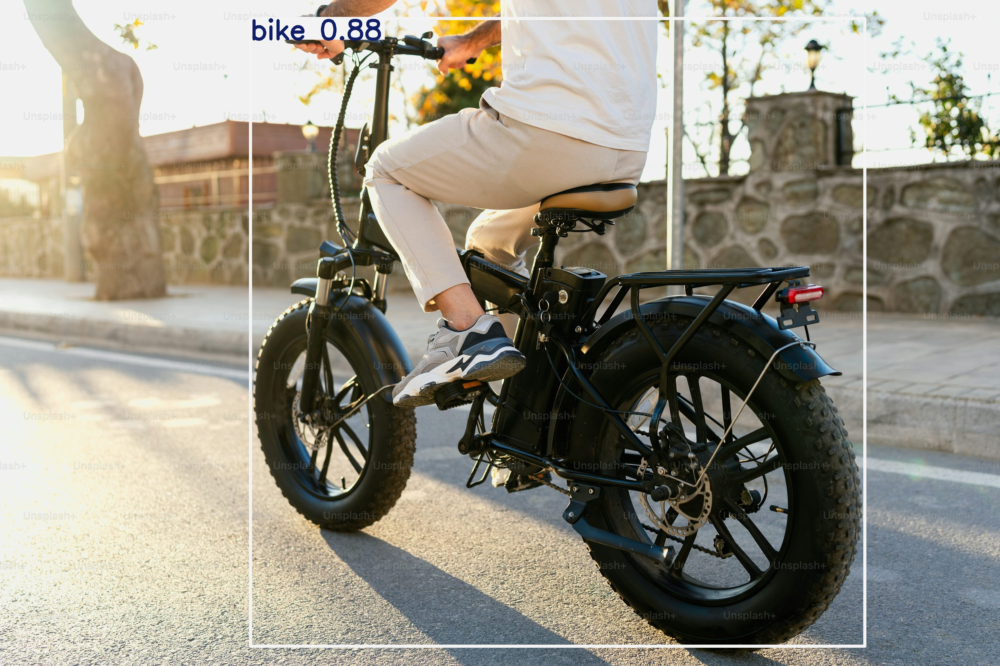

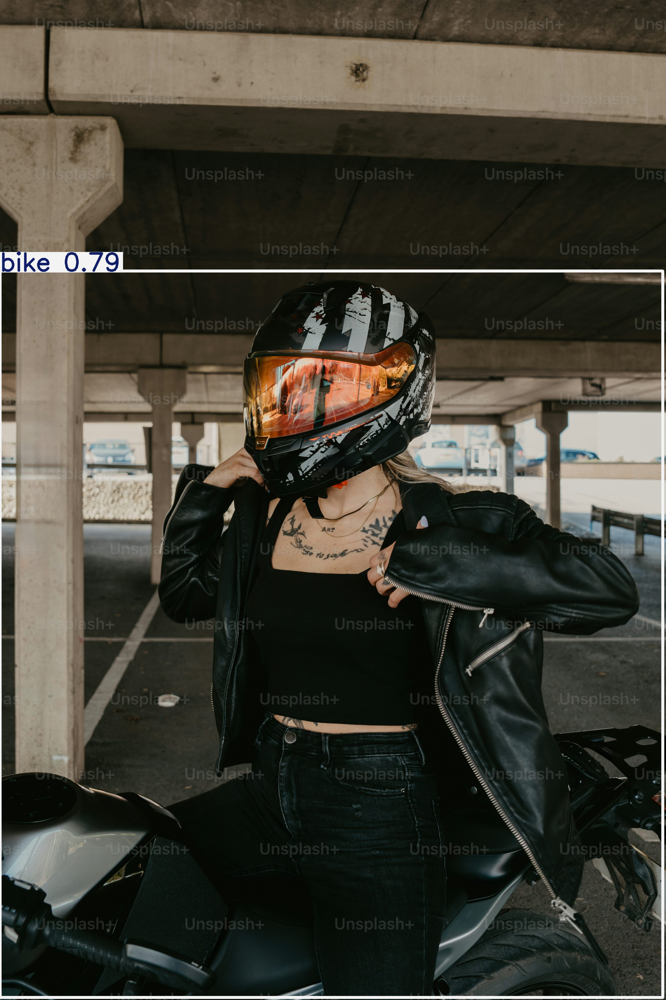

In [ ]:
import glob
from IPython.display import Image, display
for image_path in glob.glob(f'/content/runs/detect/predict/*.jpg')[:10]:
  display(Image(filename=image_path, height=400))
  print('\n')

### Validated results are backed up in drive

In [ ]:
import shutil, os

src_dir = "/content/runs/detect/predict"
dst_dir = "/content/drive/MyDrive/Vehicle_Data/runs/validated/ouputs/predict"

# Ensure the parent directory for the destination exists
os.makedirs(os.path.dirname(dst_dir), exist_ok=True)

# Remove the destination directory if it already exists, as shutil.copytree expects it not to
if os.path.exists(dst_dir):
    shutil.rmtree(dst_dir)

# Copy the directory
shutil.copytree(src_dir, dst_dir)
print("✅ Predict outputs backed up to Google Drive!")

✅ Predict outputs backed up to Google Drive!


### Download Trained YOLO model

In [ ]:
# Create "my_model" folder to store model weights and train results
!mkdir /content/my_model
!cp /content/runs/detect/train/weights/best.pt /content/my_model/my_model.pt
!cp -r /content/runs/detect/train /content/my_model

# Zip into "my_model.zip"
%cd my_model
!zip /content/my_model.zip my_model.pt
!zip -r /content/my_model.zip train
%cd /content

#